In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/robinaz/equitiesdat/equities.csv


# Comparison of Two Means: FTSE 100, BP and Shell

## Step 0: Attach the data

We use the same `equities.csv` file as in the hypothesis testing tutorial.

1. In the right-hand panel, click **Add Input**.
2. Go to **Your Work**, select **equitiesdat**, then click **+**.
3. Run the cell below. It should print the file path.

In [2]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/robinaz/equitiesdat/equities.csv


## Step 1: Introduction

Last week we tested **one** mean: *is the FTSE 100 average daily return different from zero?*
This week we compare **two** means: *is the average of group 1 different from group 2?*

| Part | Data | Type |
|---|---|---|
| A | `FTSE100`: 2015–2019 vs 2020–2025 | Independent samples |
| B | `BP` vs `SHEL` on the same days | Paired samples |

## Step 2: Choosing the right test

**Question 1: Can I pair them up?**

| Example | Can I pair them up? | Type |
|---|---|---|
| FTSE 100 in 2015–2019 vs 2020–2025 | No, different days, different group sizes | Independent |
| BP vs Shell on the same day | Yes, same day | Paired |

**Question 2: Is the population standard deviation (σ) known or unknown?**

| σ | Test | In finance |
|---|---|---|
| Known | z-test | Almost never: we cannot know the true σ of returns |
| Unknown | **t-test** (we estimate σ with the sample s) | **Our case** |

**Question 3 (independent only): Are the two variances equal?**
If the standard deviations look clearly different, use the **unequal variances** t-test (`equal_var=False`).

| Situation | Python |
|---|---|
| Independent, σ unknown, unequal variances | `stats.ttest_ind(x, y, equal_var=False)` |
| Paired, σ unknown | `stats.ttest_rel(x, y)` |

## Step 3: Formulating the hypotheses

The claim you want to find evidence for always goes in **H₁**.

| Claim | H₀ | H₁ | Test |
|---|---|---|---|
| The two means are **different** | μ₁ = μ₂ | μ₁ ≠ μ₂ | two-tailed |
| Mean 1 is **greater** | μ₁ ≤ μ₂ | μ₁ > μ₂ | right-tailed |
| Mean 1 is **smaller** | μ₁ ≥ μ₂ | μ₁ < μ₂ | left-tailed |

For **paired** data we test the mean of the differences instead: **H₀: μd = 0** vs **H₁: μd ≠ 0**.

**Small example:** an analyst claims Tech firms earn **more** than Utilities.
→ H₀: μ_Tech ≤ μ_Util, H₁: μ_Tech > μ_Util (right-tailed).

## Step 4: Import libraries and load the data

Daily log returns (%): $r_t = 100 \times \ln(P_t / P_{t-1})$

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

alpha = 0.05     # 5% significance level

equities = pd.read_csv("/kaggle/input/datasets/robinaz/equitiesdat/equities.csv",
                       parse_dates=["Date"], index_col="Date")
equities.head()

,FTSE100,BP,SHEL,HSBA
Date,,,,
2015-01-02,6547.7998,407.6302,2155.1306,608.0831
2015-01-05,6417.2002,387.0229,2067.6538,600.0351
2015-01-06,6366.5000,388.3635,2067.1562,589.9005
2015-01-07,6419.7998,391.0449,2085.5464,597.1536
2015-01-08,6570.0000,402.2176,2129.7822,602.3204


# Part A: Independent Samples t-test

## Step 5: FTSE 100 in two periods

* **Group 1:** 2015–2019 (pre-COVID)
* **Group 2:** 2020–2025 (COVID and after)

**Why independent?** Each trading day appears in **only one** group. A day in 2016 has no partner day in 2022,
so we **cannot pair them up**. It is the same index, but no day is measured twice.

### Which t-test? Equal or unequal variances

The population standard deviations σ₁ and σ₂ are **unknown**, so we use a t-test. We must also make an assumption about the two population variances:

| Assumption | Test | Python |
|---|---|---|
| σ₁² = σ₂² (equal variances) | **Pooled** t-test | `stats.ttest_ind(g1, g2, equal_var=True)` |
| σ₁² ≠ σ₂² (unequal variances) | **Welch** t-test | `stats.ttest_ind(g1, g2, equal_var=False)` |



### First, calculate the sample mean and variance of each period

In [4]:
ftse = equities["FTSE100"].dropna()
ftse_ret = (np.log(ftse).diff() * 100).dropna()     # daily log returns (%)

g1 = ftse_ret.loc["2015":"2019"]     # group 1
g2 = ftse_ret.loc["2020":"2025"]     # group 2

pd.DataFrame({
    "n":        [len(g1), len(g2)],
    "Mean (%)": [g1.mean(), g2.mean()],
    "Std (%)":  [g1.std(), g2.std()]
}, index=["2015-2019", "2020-2025"]).round(4)

,n,Mean (%),Std (%)
2015-2019,1263,0.0112,0.8705
2020-2025,1514,0.0182,1.0527


**Look at the table:**
* Different group sizes (1263 vs 1514): another sign there is no pairing.
* σ is **unknown**, so we use the sample standard deviation → **t-test**.
* The standard deviation is larger in 2020–2025 (1.05% vs 0.87%) because of the COVID swings.
* **Our choice:** we **assume unequal variances** and use the **Welch t-test** (`equal_var=False`).
  If we assumed equal variances, we would use the **pooled t-test** (`equal_var=True`).

> With large samples like ours, both tests give almost the same answer. With small samples they can differ, so always state your assumption.

## Step 6: Hypotheses

**Claim:** the FTSE 100 earned a **different** average daily return after 2020.

* **H₀: μ₁ = μ₂**
* **H₁: μ₁ ≠ μ₂** → two-tailed test

Reject H₀ if **p-value < 0.05**.

## Step 7: t-test and 95% confidence interval

In [5]:
result_ind = stats.ttest_ind(g1, g2, equal_var=False)    # σ unknown, unequal variances
ci_ind = result_ind.confidence_interval(confidence_level=0.95)

print(f"Difference (x̄1 − x̄2) = {g1.mean() - g2.mean():.4f}%")
print(f"t statistic           = {result_ind.statistic:.4f}")
print(f"p-value               = {result_ind.pvalue:.4f}")
print(f"95% CI for μ1 − μ2    = ({ci_ind.low:.4f}%, {ci_ind.high:.4f}%)")

print("Decision: reject H₀" if result_ind.pvalue < alpha else "Decision: do not reject H₀")

Difference (x̄1 − x̄2) = -0.0070%
t statistic           = -0.1912
p-value               = 0.8484
95% CI for μ1 − μ2    = (-0.0785%, 0.0646%)
Decision: do not reject H₀


**Interpretation:**
* The difference is tiny (**−0.0062%** a day), and t = **−0.17** is very close to 0.
* p = **0.866** > 0.05 → **do not reject H₀**.
* The 95% CI (−0.078%, 0.065%) **contains 0**, which gives the same decision.
* **Conclusion:** there is **no evidence** that the FTSE 100 average daily return changed after 2020.

**Remember:** "do not reject H₀" does **not** prove the means are equal. The data simply cannot tell them apart.

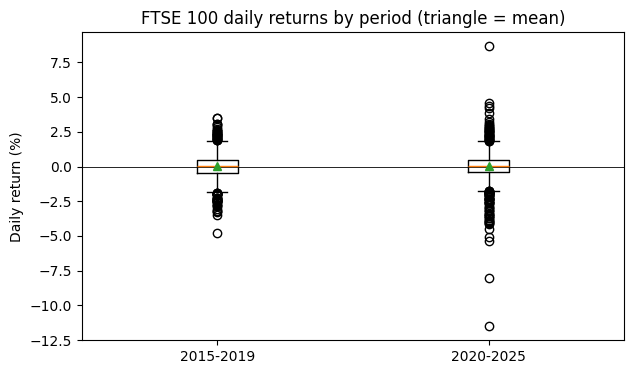

In [6]:
plt.figure(figsize=(7, 4))
plt.boxplot([g1, g2], showmeans=True)
plt.xticks([1, 2], ["2015-2019", "2020-2025"])
plt.axhline(0, color="black", lw=0.6)
plt.ylabel("Daily return (%)")
plt.title("FTSE 100 daily returns by period (triangle = mean)")
plt.show()

**What to notice:** the two means (triangles) are almost the same, near zero, but 2020–2025 is more spread out.

# Part B: Paired Samples t-test

## Step 8: BP vs Shell

BP and Shell are observed on the **same trading days**. Each BP return has a partner, **Shell's return on the same day**,
so we **can pair them up**. For each day: **d = BP return − Shell return**

In [7]:
pair = equities[["BP", "SHEL"]].dropna()                # days when both traded
pair = (np.log(pair).diff() * 100).dropna()             # daily log returns (%)
d = pair["BP"] - pair["SHEL"]                           # daily difference

print(f"BP mean     = {pair['BP'].mean():.4f}%")
print(f"SHEL mean   = {pair['SHEL'].mean():.4f}%")
print(f"Mean of d   = {d.mean():.4f}%")
print(f"Correlation = {pair['BP'].corr(pair['SHEL']):.2f}")

BP mean     = 0.0021%
SHEL mean   = 0.0086%
Mean of d   = -0.0065%
Correlation = 0.87


**Small explanation:** the correlation is about **0.87**. BP and Shell move together, so they are **not independent**.
The paired test works on the single column **d** and tests whether its mean is 0.

## Step 9: Hypotheses Formulation

**Claim:** BP and Shell had **different** average daily returns.

* **H₀: μd = 0**
* **H₁: μd ≠ 0** → two-tailed test

## Step 10: Paired t-test and 95% confidence interval

In [8]:
result_pair = stats.ttest_rel(pair["BP"], pair["SHEL"])     # σ unknown, paired
ci_pair = result_pair.confidence_interval(confidence_level=0.95)

print(f"t statistic     = {result_pair.statistic:.4f}")
print(f"p-value         = {result_pair.pvalue:.4f}")
print(f"95% CI for μd   = ({ci_pair.low:.4f}%, {ci_pair.high:.4f}%)")

print("Decision: reject H₀" if result_pair.pvalue < alpha else "Decision: do not reject H₀")

t statistic     = -0.3601
p-value         = 0.7188
95% CI for μd   = (-0.0418%, 0.0289%)
Decision: do not reject H₀


**Interpretation:**
* p > 0.05 → **do not reject H₀**: there is **no evidence** that BP and Shell have different average daily returns.
* The 95% CI **contains 0**, which gives the same decision.
* This matches last week's result: a paired t-test is the same as a one-sample t-test on d.

## Step 11: Summary

| | Part A | Part B |
|---|---|---|
| Can we pair them up? | No | Yes (same day) |
| σ known? | No → t-test | No → t-test |
| Test | `ttest_ind(..., equal_var=False)` | `ttest_rel` |
| H₀ | μ₁ = μ₂ | μd = 0 |
| Decision | Do not reject H₀ | Do not reject H₀ |
